In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

import ipywidgets as widgets
from IPython.display import display, clear_output

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

np.random.seed(42)

n = 3000

df = pd.DataFrame({
    "Age": np.random.randint(18, 90, n),
    "BMI": np.random.uniform(16, 42, n).round(1),
    "SystolicBP": np.random.randint(90, 190, n),
    "DiastolicBP": np.random.randint(55, 120, n),
    "Glucose": np.random.randint(65, 220, n),
    "HeartRate": np.random.randint(50, 125, n),
    "Cholesterol": np.random.randint(120, 320, n),
    "ActivityMinutes": np.random.randint(0, 120, n)
})

def risk_category(row):
    score = 0
    score += int(row["Age"] >= 60)
    score += int(row["BMI"] >= 30)
    score += int(row["SystolicBP"] >= 140 or row["DiastolicBP"] >= 90)
    score += int(row["Glucose"] >= 126)
    score += int(row["HeartRate"] >= 100)
    score += int(row["Cholesterol"] >= 240)
    score += int(row["ActivityMinutes"] < 15)

    if score <= 1:
        return "Low"
    elif score <= 3:
        return "Moderate"
    else:
        return "High"

df["RiskCategory"] = df.apply(risk_category, axis=1)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Dataset created successfully!
Dataset shape: (3000, 9)


,Age,BMI,SystolicBP,DiastolicBP,Glucose,HeartRate,Cholesterol,ActivityMinutes,RiskCategory
0,69,40.5,152,87,181,52,186,62,High
1,32,27.0,174,86,127,79,172,89,Moderate
2,89,25.8,153,118,119,80,201,45,Moderate
3,78,40.3,109,93,89,83,229,90,Moderate
4,38,33.6,97,96,90,69,264,106,Moderate
5,41,19.0,147,63,127,103,172,91,Moderate
6,20,17.1,135,79,137,74,275,19,Moderate
7,39,30.7,120,56,143,64,233,69,Moderate
8,70,40.2,182,73,129,87,182,7,High
9,19,38.0,98,74,133,72,262,95,Moderate


In [ ]:

print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe().round(2))

print("\nMissing Values:")
display(df.isnull().sum())

print("\nRisk Category Counts:")
display(df["RiskCategory"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              3000 non-null   int64  
 1   BMI              3000 non-null   float64
 2   SystolicBP       3000 non-null   int64  
 3   DiastolicBP      3000 non-null   int64  
 4   Glucose          3000 non-null   int64  
 5   HeartRate        3000 non-null   int64  
 6   Cholesterol      3000 non-null   int64  
 7   ActivityMinutes  3000 non-null   int64  
 8   RiskCategory     3000 non-null   object 
dtypes: float64(1), int64(7), object(1)
memory usage: 211.1+ KB
None

Statistical Summary:


,Age,BMI,SystolicBP,DiastolicBP,Glucose,HeartRate,Cholesterol,ActivityMinutes
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,52.89,28.98,139.79,87.05,140.78,87.38,218.32,59.93
std,20.68,7.47,28.72,18.64,45.29,21.75,57.04,34.78
min,18.00,16.00,90.00,55.00,65.00,50.00,120.00,0.00
25%,35.00,22.60,115.00,71.00,101.00,68.00,169.00,30.00
50%,52.00,29.00,140.00,87.00,141.00,87.00,217.00,60.00
75%,71.00,35.50,165.00,103.00,180.00,106.00,267.00,90.00
max,89.00,42.00,189.00,119.00,219.00,124.00,319.00,119.00



Missing Values:


,0
Age,0
BMI,0
SystolicBP,0
DiastolicBP,0
Glucose,0
HeartRate,0
Cholesterol,0
ActivityMinutes,0
RiskCategory,0



Risk Category Counts:


,count
RiskCategory,
Moderate,1709
High,1024
Low,267


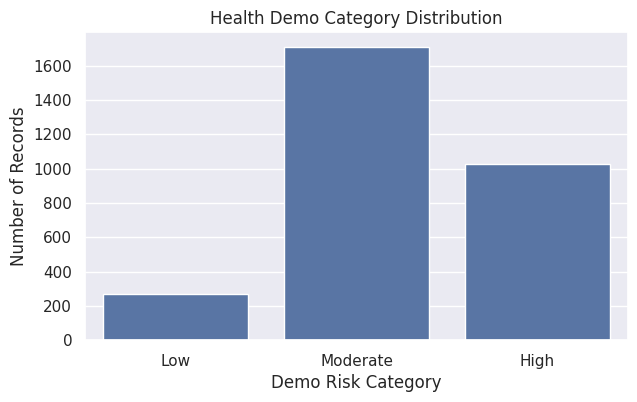

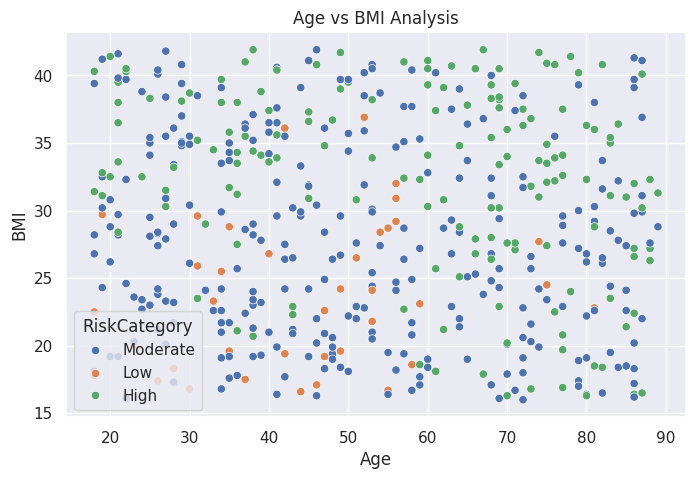

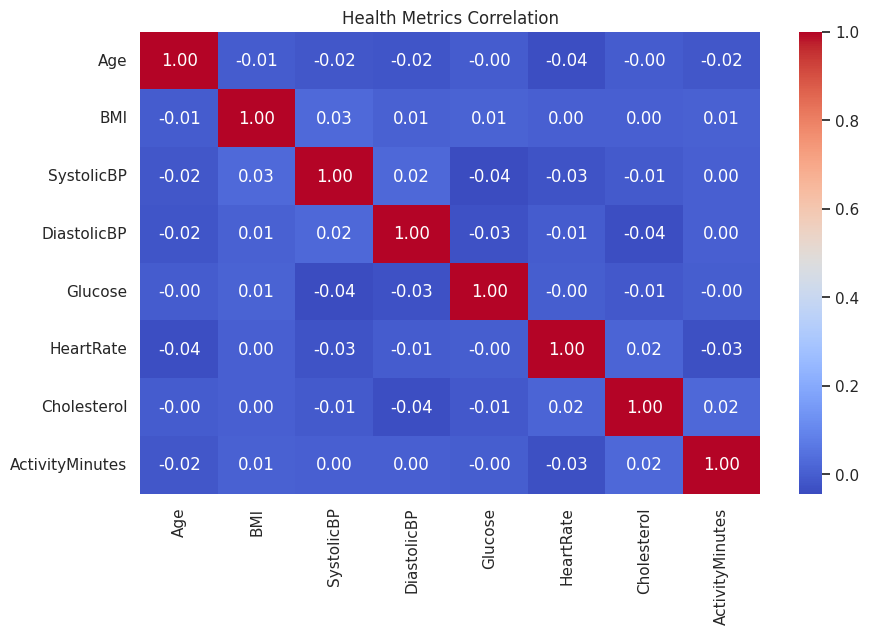

In [ ]:

sns.set_theme()

# Risk category chart
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x="RiskCategory",
    order=["Low", "Moderate", "High"]
)
plt.title("Health Demo Category Distribution")
plt.xlabel("Demo Risk Category")
plt.ylabel("Number of Records")
plt.show()

# Age vs BMI
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(500, random_state=42),
    x="Age",
    y="BMI",
    hue="RiskCategory"
)
plt.title("Age vs BMI Analysis")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Health Metrics Correlation")
plt.show()


In [ ]:

features = [
    "Age", "BMI", "SystolicBP", "DiastolicBP",
    "Glucose", "HeartRate", "Cholesterol",
    "ActivityMinutes"
]

X = df[features]
y = df["RiskCategory"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Training Completed!")
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Training Completed!
Test Accuracy: 93.67 %

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.92      0.93       205
         Low       1.00      0.85      0.92        53
    Moderate       0.93      0.96      0.95       342

    accuracy                           0.94       600
   macro avg       0.95      0.91      0.93       600
weighted avg       0.94      0.94      0.94       600



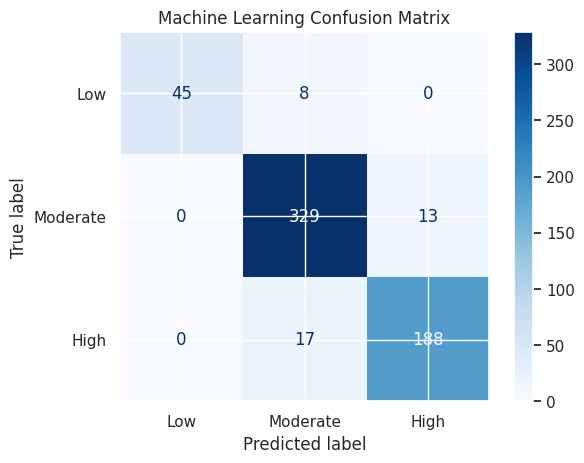

In [ ]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Low", "Moderate", "High"],
    cmap="Blues"
)

plt.title("Machine Learning Confusion Matrix")
plt.show()


,Feature,Importance
1,BMI,0.175783
4,Glucose,0.158211
5,HeartRate,0.140335
6,Cholesterol,0.134401
0,Age,0.131257
2,SystolicBP,0.096509
3,DiastolicBP,0.084970
7,ActivityMinutes,0.078533


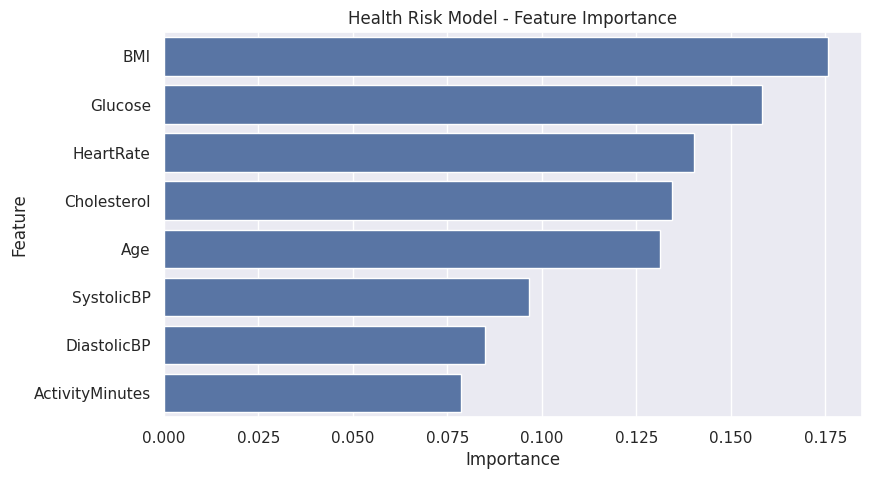

In [ ]:

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Health Risk Model - Feature Importance")
plt.show()


In [ ]:

age = widgets.IntSlider(
    value=35, min=18, max=90, description="Age"
)
bmi = widgets.FloatSlider(
    value=24, min=16, max=42, step=0.5, description="BMI"
)
sbp = widgets.IntSlider(
    value=118, min=90, max=190, description="Systolic BP"
)
dbp = widgets.IntSlider(
    value=78, min=55, max=120, description="Diastolic BP"
)
glucose = widgets.IntSlider(
    value=95, min=65, max=220, description="Glucose"
)
heart = widgets.IntSlider(
    value=72, min=50, max=125, description="Heart Rate"
)
chol = widgets.IntSlider(
    value=175, min=120, max=320, description="Cholesterol"
)
activity = widgets.IntSlider(
    value=30, min=0, max=120, description="Activity"
)

button = widgets.Button(
    description="Predict Demo Category",
    button_style="success"
)

output = widgets.Output()

def predict_health(b):
    with output:
        clear_output(wait=True)

        sample = pd.DataFrame([{
            "Age": age.value,
            "BMI": bmi.value,
            "SystolicBP": sbp.value,
            "DiastolicBP": dbp.value,
            "Glucose": glucose.value,
            "HeartRate": heart.value,
            "Cholesterol": chol.value,
            "ActivityMinutes": activity.value
        }], columns=features)

        prediction = model.predict(sample)[0]
        probabilities = model.predict_proba(sample)[0]

        print("EDUCATIONAL DEMO — NOT A MEDICAL DIAGNOSIS")
        print("Predicted Demo Category:", prediction)

        probability_df = pd.DataFrame({
            "Category": model.classes_,
            "Model Probability": probabilities
        })

        display(probability_df)

        sns.barplot(
            data=probability_df,
            x="Category",
            y="Model Probability"
        )
        plt.title("Classifier Output Probabilities")
        plt.ylim(0, 1)
        plt.show()

button.on_click(predict_health)

display(widgets.VBox([
    age, bmi, sbp, dbp,
    glucose, heart, chol, activity,
    button, output
]))


In [ ]:

from google.colab import files
from datetime import datetime

sample = pd.DataFrame([{
    "Age": age.value,
    "BMI": bmi.value,
    "SystolicBP": sbp.value,
    "DiastolicBP": dbp.value,
    "Glucose": glucose.value,
    "HeartRate": heart.value,
    "Cholesterol": chol.value,
    "ActivityMinutes": activity.value
}], columns=features)

prediction = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]

report = sample.copy()
report["DemoCategory"] = prediction
report["GeneratedAt"] = datetime.now().strftime(
    "%Y-%m-%d %H:%M:%S"
)
report["Disclaimer"] = "Synthetic educational demo only"

report.to_csv("health_risk_report.csv", index=False)

display(report)

files.download("health_risk_report.csv")


,Age,BMI,SystolicBP,DiastolicBP,Glucose,HeartRate,Cholesterol,ActivityMinutes,DemoCategory,GeneratedAt,Disclaimer
0,35,24.0,118,78,95,72,175,30,Low,2026-10-21 07:40:22,Synthetic educational demo only


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>